# Zero-Shot Evaluation

## Imports/Path 

In [124]:
import json
import subprocess
from datetime import datetime
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from datetime import datetime
from transformers import TimesFm2_5ModelForPrediction
import torch
from tqdm.auto import tqdm

In [159]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

In [166]:
FIGURES_DIR.mkdir(parents=True,exist_ok=True)

In [127]:
ae = pd.read_csv(DATA_DIR/"ae_minute_data.csv")
dst = pd.read_csv(DATA_DIR/"dst_data.csv",header=None)
kp = pd.read_csv(DATA_DIR/"kp_data.csv",header=None)

In [128]:
kp.columns = ["timestamp", "kp", "ap", "version_code"]
kp = kp[["timestamp", "kp"]]
kp["timestamp"] = pd.to_datetime(kp["timestamp"],utc=True)

kp = kp.loc[
    kp["timestamp"] >= "2000-01-01"
].reset_index(drop=True)
kp

,timestamp,kp
0,2000-01-01 01:30:00+00:00,5.3
1,2000-01-01 04:30:00+00:00,4.7
2,2000-01-01 07:30:00+00:00,4.0
3,2000-01-01 10:30:00+00:00,3.3
4,2000-01-01 13:30:00+00:00,4.3
...,...,...
60627,2020-09-30 10:30:00+00:00,2.7
60628,2020-09-30 13:30:00+00:00,2.0
60629,2020-09-30 16:30:00+00:00,1.7
60630,2020-09-30 19:30:00+00:00,3.3


In [129]:
dst.columns = ["timestamp", "dst", "version_code"]
dst = dst[["timestamp", "dst"]]
dst["timestamp"] = pd.to_datetime(dst["timestamp"],utc=True)

dst = dst.loc[
    dst["timestamp"] >= "2000-01-01"
].reset_index(drop=True)

dst

,timestamp,dst
0,2000-01-01 00:29:30+00:00,-45
1,2000-01-01 01:29:30+00:00,-37
2,2000-01-01 02:29:30+00:00,-37
3,2000-01-01 03:29:30+00:00,-41
4,2000-01-01 04:29:30+00:00,-45
...,...,...
181891,2020-09-30 19:29:30+00:00,-29
181892,2020-09-30 20:29:30+00:00,-32
181893,2020-09-30 21:29:30+00:00,-31
181894,2020-09-30 22:29:30+00:00,-31


In [130]:
ae = ae[["timestamp", "ae_nt"]]
ae["timestamp"] = pd.to_datetime(ae["timestamp"], utc=True)
ae

,timestamp,ae_nt
0,2000-01-01 00:00:00+00:00,668
1,2000-01-01 00:01:00+00:00,638
2,2000-01-01 00:02:00+00:00,666
3,2000-01-01 00:03:00+00:00,615
4,2000-01-01 00:04:00+00:00,554
...,...,...
10913755,2020-09-30 23:55:00+00:00,121
10913756,2020-09-30 23:56:00+00:00,97
10913757,2020-09-30 23:57:00+00:00,89
10913758,2020-09-30 23:58:00+00:00,81


In [131]:
ae_hourly = (
    ae.set_index("timestamp")
      .resample("1h")
      .mean()
)

In [132]:
ae_15min = (
    ae.set_index("timestamp")
      .resample("15min")
      .mean()
)

print(ae_15min.head())
print("Missing intervals:", ae_15min.isna().sum())

                                ae_nt
timestamp                            
2000-01-01 00:00:00+00:00  565.000000
2000-01-01 00:15:00+00:00  605.466667
2000-01-01 00:30:00+00:00  506.533333
2000-01-01 00:45:00+00:00  390.866667
2000-01-01 01:00:00+00:00  227.933333
Missing intervals: ae_nt    0
dtype: int64


In [160]:
model = TimesFm2_5ModelForPrediction.from_pretrained(
    "google/timesfm-2.5-200m-transformers",
    device_map="auto",
)
model = model.to(device)

Loading weights: 100%|██████████| 272/272 [00:01<00:00, 232.19it/s]


### [Walking Forward Validation](https://medium.com/@ahmedfahad04/understanding-walk-forward-validation-in-time-series-analysis-a-practical-guide-ea3814015abf)

We will be using Walking Forward Validation for our Multivariate time-series so we can capture the evolving temporal relationship of the data.

$C = 168, H = 24, S = 24$

Where:
- $C$ : Context Length (Historical Observations)
- $H$ : Forecast Horizon (Timespan of Future Observations)
- $S$ : Stride (How much we advance between forecasts)

$X_t = [x_{t-C+1},...,x_t]$

$Y_T = [x_{t+1},...,x_{t+H}]$

In [134]:
dst_values = dst["dst"].to_numpy(dtype=float)
kp_values = kp["kp"].to_numpy(dtype=float)
ae_values = ae_15min["ae_nt"].to_numpy(dtype=float)

In [135]:
configs = {
    "dst": {"values": dst_values, "context_len": 168, "horizon_len": 24, "stride": 24},
    "kp":  {"values": kp_values,  "context_len": 56,  "horizon_len": 8,  "stride": 8},
    "ae":  {"values": ae_values,  "context_len": 672, "horizon_len": 96, "stride": 96},
}

In [136]:
def generate_windows(series, context_len, horizon_len, stride):
    for start in range(0, len(series)-context_len-horizon_len+1,stride):
        context = series[start:start+context_len]
        target = series [start+context_len:start+context_len+horizon_len]

        yield context,target

In [137]:
save_dir = RESULTS_DIR / Path("zero_shot")
save_dir.mkdir(parents=True, exist_ok=True)
batch_size = 64

z_results = {
    "dst": {"predictions": [], "targets": []},
    "kp":  {"predictions": [], "targets": []},
    "ae":  {"predictions": [], "targets": []},
}


model.eval()

with torch.inference_mode():
    for index_name, config in configs.items():

        values = config["values"]
        context_len = config["context_len"]
        horizon = config["horizon_len"]
        stride = config["stride"]

        checkpoint = save_dir / f"{index_name}_zero_shot.npz"

        origins = range(
            context_len,
            len(values) - horizon + 1,
            stride
        )

        # Resume completed forecasts
        if checkpoint.exists():
            with np.load(checkpoint) as saved:
                predictions = list(saved["predictions"])
                targets = list(saved["targets"])

            completed = len(predictions)
            print(f"{index_name.upper()}: Resuming from {completed} forecasts")
        else:
            predictions = []
            targets = []
            completed = 0

        for batch_start in tqdm(
            range(completed, len(origins), batch_size),
            desc=f"{index_name.upper()} Zero-shot"
        ):
            batch_origins = origins[batch_start:batch_start + batch_size]

            contexts = []
            batch_targets = []

            for start in batch_origins:
                contexts.append(
                    torch.as_tensor(
                        values[start-context_len:start],
                        dtype=torch.float32,
                        device=model.device
                    )
                )
                batch_targets.append(values[start:start+horizon])

            forecast = model(
                past_values=contexts,
                return_dict=True
            )

            batch_predictions = (
                forecast.mean_predictions[:, :horizon]
                .cpu()
                .numpy()
            )

            predictions.extend(batch_predictions)
            targets.extend(batch_targets)

            # Save progress after every batch
            np.savez_compressed(
                checkpoint,
                predictions=np.asarray(predictions),
                targets=np.asarray(targets)
            )

        z_results[index_name] = {
            "predictions": predictions,
            "targets": targets
        }

        print(f"{index_name.upper()}: {len(predictions)} forecasts saved")

DST: Resuming from 7572 forecasts


DST Zero-shot: 0it [00:00, ?it/s]


DST: 7572 forecasts saved
KP: Resuming from 7572 forecasts


KP Zero-shot: 0it [00:00, ?it/s]


KP: 7572 forecasts saved
AE: Resuming from 7572 forecasts


AE Zero-shot: 0it [00:00, ?it/s]

AE: 7572 forecasts saved


In [138]:
for index_name, result in z_results.items():
    predictions = np.array(result["predictions"])
    targets = np.array(result["targets"])

    mae = np.mean(np.abs(predictions - targets))
    print(f"{index_name}: MAE = {mae:.4f}")

dst: MAE = 8.1861
kp: MAE = 0.8693
ae: MAE = 112.5880


In [139]:
# from sklearn.metrics import mean_absolute_error

# timesfm_mae = mean_absolute_error(
#     np.asarray(targets).flatten(),
#     np.asarray(predictions).flatten()
# )

# print(f"Zero Shot MAE: {timesfm_mae:.4f} nT")

In [140]:
# plt.figure(figsize=(12, 5))

# plt.plot(targets[0], label="Actual Dst", marker="o")
# plt.plot(predictions[0], label="TimesFM Zero-Shot", marker="x")

# plt.xlabel("Forecast Horizon (Hours)")
# plt.ylabel("Dst (nT)")
# plt.title("TimesFM 2.5 Zero-Shot Forecast vs Actual Dst")
# plt.legend()
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()

In [141]:
p_results = {
    "dst": {"predictions": [], "targets": []},
    "kp":  {"predictions": [], "targets": []},
    "ae":  {"predictions": [], "targets": []},
}
for index_name, config in configs.items():
    for context, target in generate_windows(
        config["values"],
        config["context_len"],
        config["horizon_len"],
        config["stride"]
    ):
        forecast = np.full(config["horizon_len"], context[-1])
        p_results[index_name]["predictions"].append(forecast)
        p_results[index_name]["targets"].append(target)

In [142]:
for index_name, result in p_results.items():
    predictions = np.array(result["predictions"])
    targets = np.array(result["targets"])

    mae = np.mean(np.abs(predictions - targets))
    print(f"{index_name}: MAE = {mae:.4f}")

dst: MAE = 9.1675
kp: MAE = 0.9611
ae: MAE = 129.7460


In [143]:
mae_results = {
    "timesfm": {},
    "persistence": {}
}

for model_name, model_results in [
    ("timesfm", z_results),
    ("persistence", p_results)
]:
    for index_name, result in model_results.items():
        predictions = np.array(result["predictions"])
        targets = np.array(result["targets"])

        mae = np.mean(np.abs(predictions - targets))
        mae_results[model_name][index_name] = mae

In [144]:
# persistence_mae = mean_absolute_error(
#     np.asarray(persistence_predictions).flatten(),
#     np.asarray(targets).flatten()
# )

# print(f"Persistence MAE: {persistence_mae:.4f} nT")

In [145]:
# plt.figure(figsize=(12, 5))


# plt.plot(persistence_predictions[0], label="Persistence Baseline", marker="+")
# plt.plot(predictions[0], label="TimesFM Zero-Shot", marker="x")
# plt.plot(targets[0], label="Actual Dst", marker="o")

# plt.xlabel("Forecast Horizon (Hours)")
# plt.ylabel("Dst (nT)")
# plt.title("TimesFM 2.5 Zero-Shot Forecast vs Persistence Baseline")
# plt.legend()
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()

$Improvement = \frac{MAE_{Persistence}-MAE_{TimesFM2.5}}{MAE_{Persistance}}$

In [146]:
for index_name in configs:
    timesfm_mae = mae_results["timesfm"][index_name]
    persistence_mae = mae_results["persistence"][index_name]

    skill = (1 - timesfm_mae / persistence_mae) * 100

    print(f"{index_name}: {skill:.2f}%")

dst: 10.71%
kp: 9.55%
ae: 13.22%


,timesfm,persistence
dst,8.186084,9.167547
kp,0.869268,0.961077
ae,112.588018,129.745993


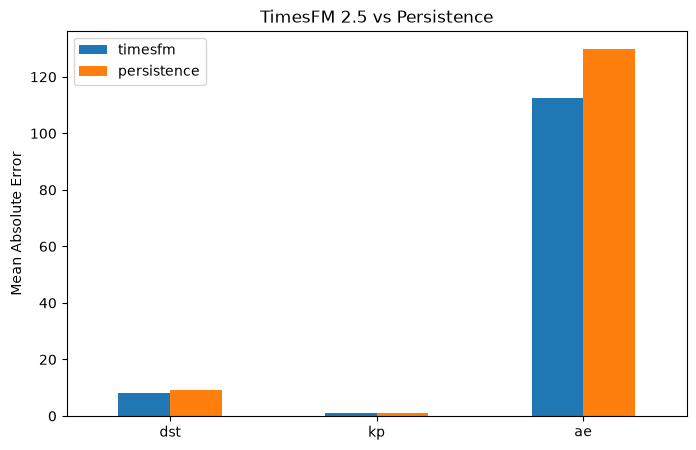

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

mae_df = pd.DataFrame(mae_results)

display(mae_df)

mae_df.plot(kind="bar", figsize=(8, 5))
plt.ylabel("Mean Absolute Error")
plt.title("TimesFM 2.5 vs Persistence")
plt.xticks(rotation=0)
plt.savefig(FIGURES_DIR / "zero_shot_vs_persistence_bar.png",
            dpi=200, bbox_inches="tight")
plt.show()

Interpretation: For both dst and kp the zero shot failed to show meaningful improvement, while with AE it is shown to have a marginal improvement.

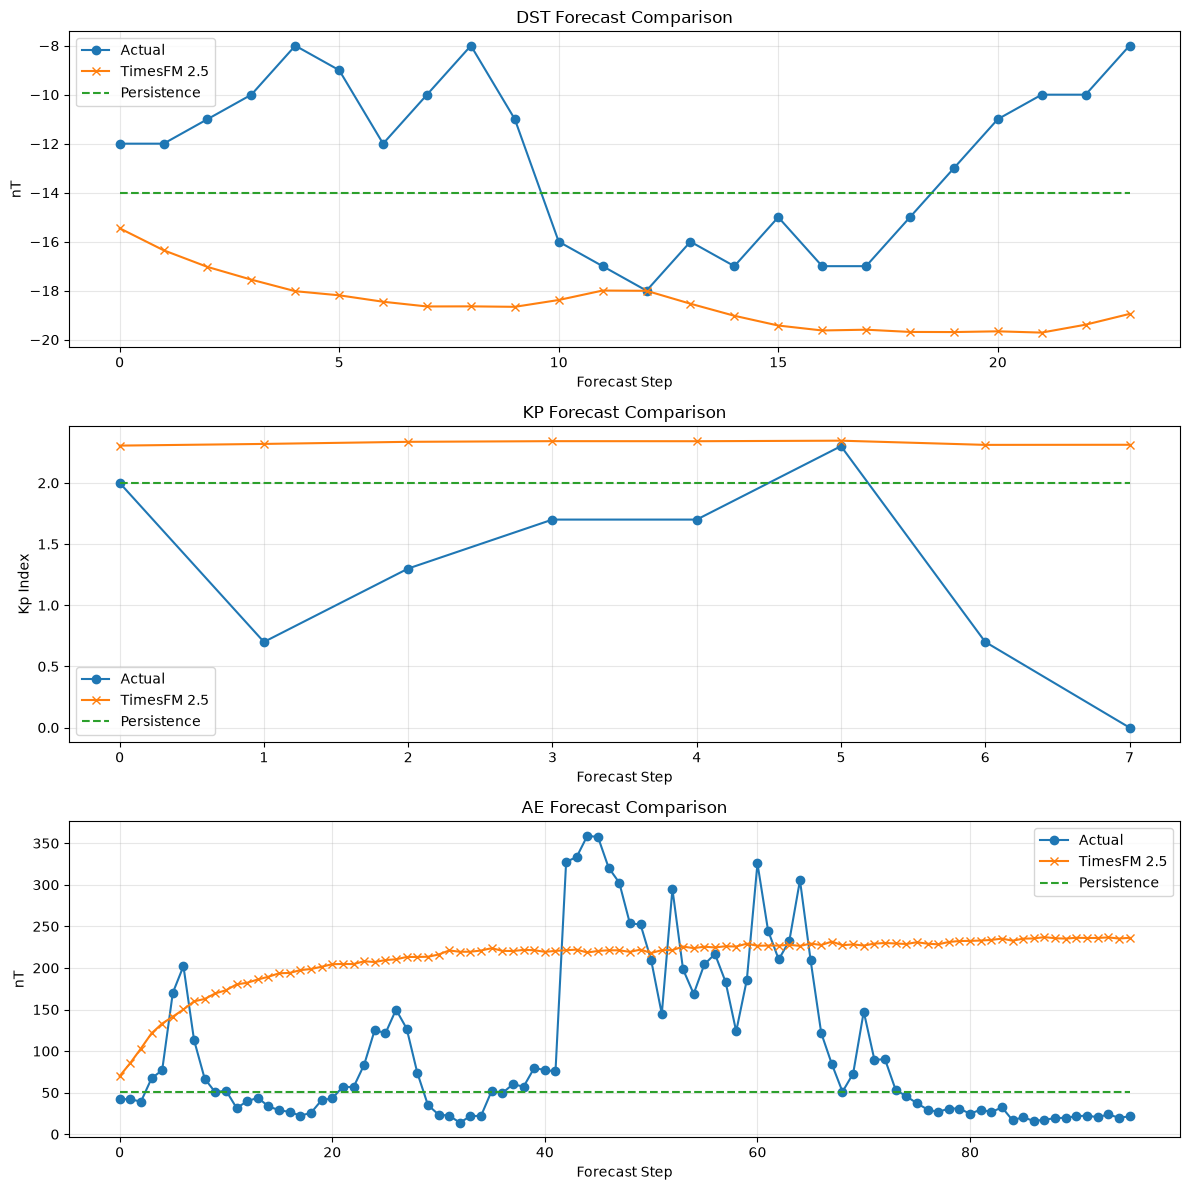

In [168]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12, 12))

for ax, index_name in zip(axes, ["dst", "kp", "ae"]):

    actual = np.array(z_results[index_name]["targets"][0])
    timesfm = np.array(z_results[index_name]["predictions"][0])
    persistence = np.array(p_results[index_name]["predictions"][0])

    steps = np.arange(len(actual))

    ax.plot(steps, actual, label="Actual", marker="o")
    ax.plot(steps, timesfm, label="TimesFM 2.5", marker="x")
    ax.plot(steps, persistence, label="Persistence", linestyle="--")

    ax.set_title(f"{index_name.upper()} Forecast Comparison")
    ax.set_xlabel("Forecast Step")
    ax.set_ylabel("nT" if index_name != "kp" else "Kp Index")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "zero_shot_vs_persistence_forecast.png",
            dpi=200, bbox_inches="tight")
plt.show()

TimesFM appears to transfer reasonably well to geomagnetic forecasting without domain-specific fine-tuning. It outperforms persistence baseline for all 3 forecasts by $9.5-13.3%$, as shown in the bar graph. When looking at the plot, it appears that the forecast produced are relatively smooth, with approximately closer values to the actual compared with persistence, suggesting that TimesFM captures broad temporal patterns but struggles to produce the rapid geomagnetic fluctuations as shown in the original. Despite this limitation, TimesFM achieves lower prediction error than persistence across all three indices.

# In-Context Experiment

In [ ]:
# import time
# import torch

# values = configs["dst"]["values"]
# context_len = 720

# for bs in [16, 32, 64, 128]:
#     contexts = [
#         torch.as_tensor(
#             values[i:i + context_len],
#             dtype=torch.float32,
#             device=model.device
#         )
#         for i in range(bs)
#     ]

#     try:
#         torch.cuda.synchronize()
#         start = time.perf_counter()

#         with torch.inference_mode():
#             forecast = model(
#                 past_values=contexts,
#                 return_dict=True
#             )

#         torch.cuda.synchronize()
#         elapsed = time.perf_counter() - start

#         print(
#             f"Batch {bs}: {elapsed:.2f}s | "
#             f"{bs / elapsed:.1f} windows/sec | "
#             f"{torch.cuda.max_memory_allocated() / 1e9:.2f} GB peak"
#         )

#         del forecast, contexts

#     except torch.cuda.OutOfMemoryError:
#         print(f"Batch {bs}: Out of memory")
#         torch.cuda.empty_cache()

In [156]:
context_lengths = [24, 72, 168, 336, 720]
sampling_hours = {
    "dst": 1,
    "kp": 3,
    "ae": 0.25
}

sweep_results = {}
batch_size = 64

In [151]:
# ae_hourly = ae["timestamp"].resample("1h").mean().dropna()

# ae_values = ae_hourly.to_numpy()

In [ ]:
results_path = PROJECT_ROOT / Path("results/context_sweep.json")
results_path.parent.mkdir(parents=True, exist_ok=True)

In [161]:
model.eval()

with torch.inference_mode():

    if results_path.exists():
        with open(results_path) as f:
            sweep_results = json.load(f)
    else:
        sweep_results = {}

    for index_name, config in configs.items():

        values = config["values"]
        horizon = config["horizon_len"]
        stride = config["stride"]

        sweep_results.setdefault(index_name, {})

        max_context = int(
            max(context_lengths) / sampling_hours[index_name]
        )

        # Fixed forecast origins across all context lengths
        origins = range(
            max_context,
            len(values) - horizon + 1,
            stride
        )

        # Persistence baseline: calculate once per index
        persistence_error = 0.0
        persistence_count = 0

        for start in origins:
            target = values[start:start + horizon]
            prediction = values[start - 1]

            persistence_error += np.abs(target - prediction).sum()
            persistence_count += target.size

        persistence_mae = persistence_error / persistence_count

        for context_hours in context_lengths:

            context_key = str(context_hours)

            if context_key in sweep_results[index_name]:
                print(
                    f"Skipping {index_name}: "
                    f"{context_hours}h (already completed)"
                )
                continue

            context_len = int(
                context_hours / sampling_hours[index_name]
            )

            total_error = 0.0
            total_count = 0

            for batch_start in tqdm(
                range(0, len(origins), batch_size),
                desc=f"{index_name.upper()} | {context_hours}h"
            ):

                batch_origins = origins[
                    batch_start:batch_start + batch_size
                ]

                batch_contexts = []
                batch_targets = []

                for start in batch_origins:

                    context = values[start - context_len:start]
                    target = values[start:start + horizon]

                    batch_contexts.append(
                        torch.as_tensor(
                            context,
                            dtype=torch.float32,
                            device=model.device
                        )
                    )

                    batch_targets.append(target)

                forecast = model(
                    past_values=batch_contexts,
                    return_dict=True
                )

                predictions = (
                    forecast.mean_predictions[:, :horizon]
                    .cpu()
                    .numpy()
                )

                targets = np.stack(batch_targets)

                total_error += np.abs(predictions - targets).sum()
                total_count += targets.size

            # TimesFM MAE
            mae = total_error / total_count

            # Relative improvement over persistence
            skill = (1 - mae / persistence_mae) * 100

            # Save both results
            sweep_results[index_name][context_key] = {
                "timesfm_mae": float(mae),
                "persistence_mae": float(persistence_mae),
                "skill_percent": float(skill)
            }

            with open(results_path, "w") as f:
                json.dump(sweep_results, f, indent=4)

            print(
                f"{index_name.upper()} | "
                f"Context: {context_hours}h | "
                f"TimesFM MAE: {mae:.4f} | "
                f"Persistence MAE: {persistence_mae:.4f} | "
                f"Skill: {skill:+.2f}%"
            )

DST | 24h: 100%|██████████| 118/118 [05:21<00:00,  2.72s/it]


DST | Context: 24h | TimesFM MAE: 8.8935 | Persistence MAE: 9.1638 | Skill: +2.95%


DST | 72h: 100%|██████████| 118/118 [05:22<00:00,  2.73s/it]


DST | Context: 72h | TimesFM MAE: 8.5029 | Persistence MAE: 9.1638 | Skill: +7.21%


DST | 168h: 100%|██████████| 118/118 [05:12<00:00,  2.65s/it]


DST | Context: 168h | TimesFM MAE: 8.1860 | Persistence MAE: 9.1638 | Skill: +10.67%


... (20 outputs left out)

AE | 336h: 100%|██████████| 118/118 [05:36<00:00,  2.85s/it]


AE | Context: 336h | TimesFM MAE: 110.0633 | Persistence MAE: 129.7471 | Skill: +15.17%


AE | 720h: 100%|██████████| 118/118 [05:28<00:00,  2.79s/it]

AE | Context: 720h | TimesFM MAE: 108.4127 | Persistence MAE: 129.7471 | Skill: +16.44%


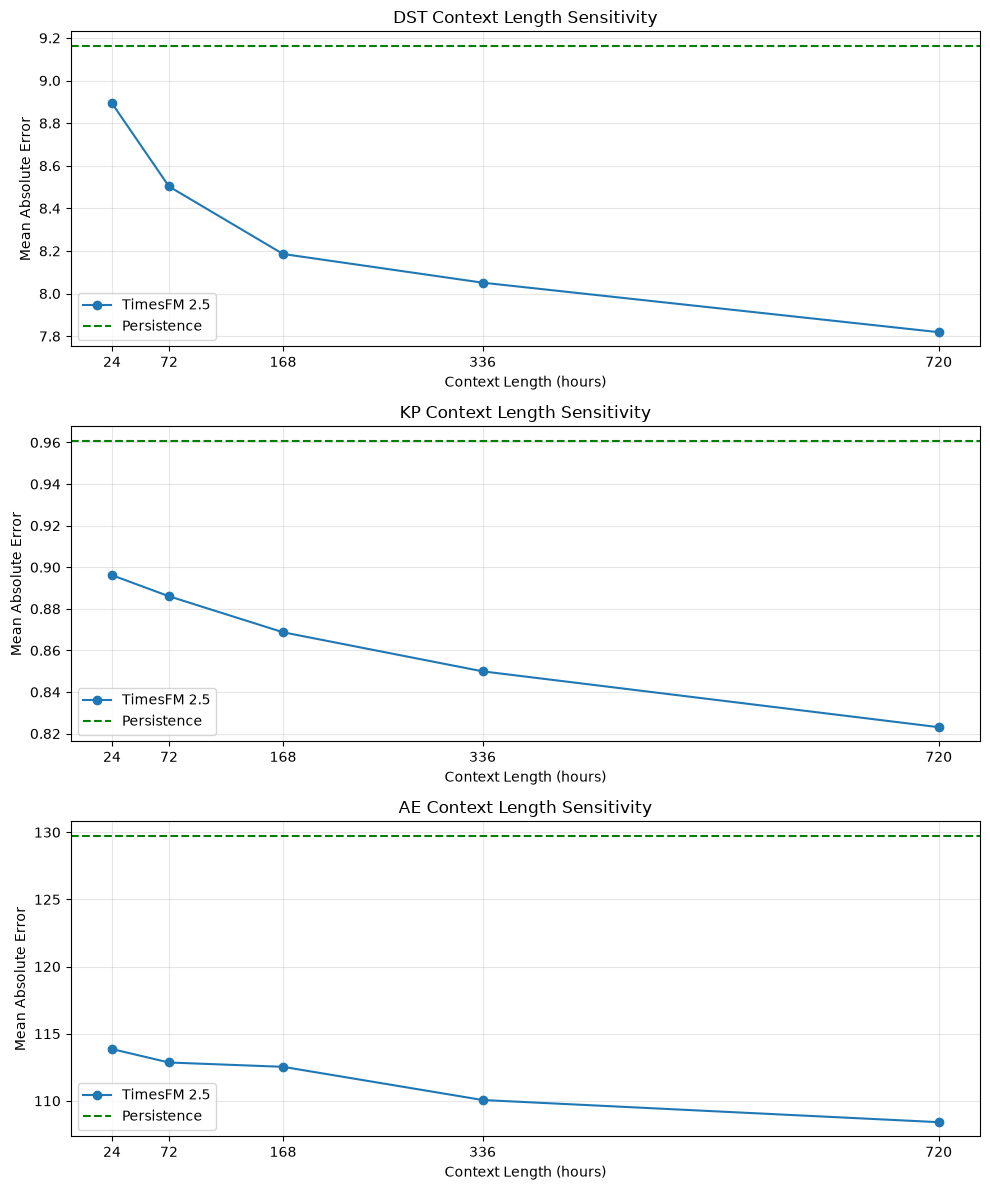

In [169]:
import pandas as pd
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(10, 12))

for ax, (index_name, results) in zip(axes, sweep_results.items()):

    df = pd.DataFrame.from_dict(results, orient="index")
    df.index = df.index.astype(int)
    df = df.sort_index()

    ax.plot(
        df.index,
        df["timesfm_mae"],
        marker="o",
        label="TimesFM 2.5"
    )

    ax.axhline(
        y=df["persistence_mae"].iloc[0],
        linestyle="--",
        color="green",
        label="Persistence"
    )

    ax.set_title(f"{index_name.upper()} Context Length Sensitivity")
    ax.set_xlabel("Context Length (hours)")
    ax.set_ylabel("Mean Absolute Error")
    ax.set_xticks(df.index)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "context_length_sensitivity.png",
            dpi=200, bbox_inches="tight")
plt.show()

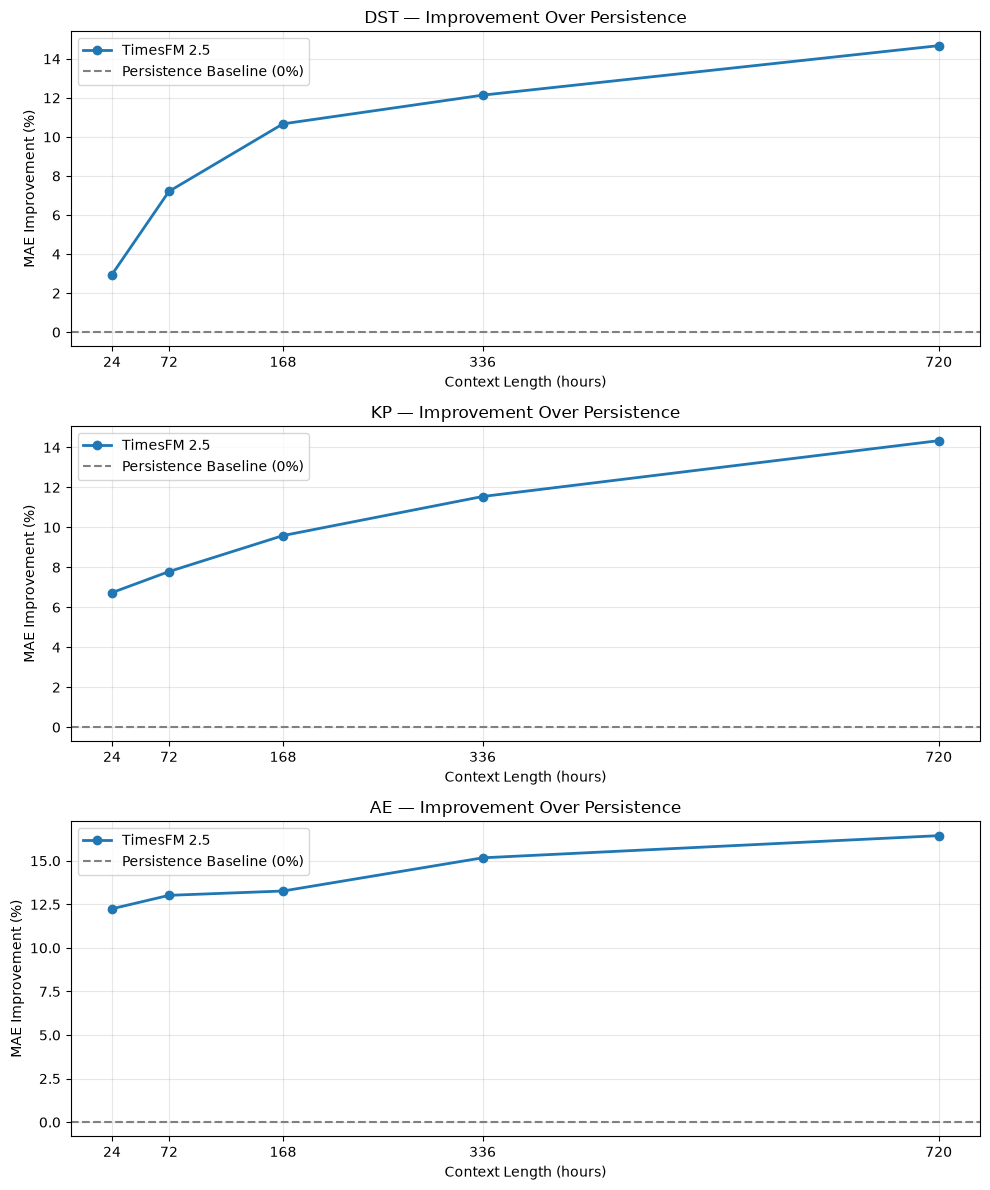

In [170]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))

for ax, (index_name, results) in zip(axes, sweep_results.items()):

    df = pd.DataFrame.from_dict(results, orient="index")
    df.index = df.index.astype(int)
    df = df.sort_index()

    ax.plot(
        df.index,
        df["skill_percent"],
        marker="o",
        linewidth=2,
        label="TimesFM 2.5"
    )

    ax.axhline(
        y=0,
        color="gray",
        linestyle="--",
        label="Persistence Baseline (0%)"
    )

    ax.set_title(f"{index_name.upper()} — Improvement Over Persistence")
    ax.set_xlabel("Context Length (hours)")
    ax.set_ylabel("MAE Improvement (%)")
    ax.set_xticks(df.index)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "context_length_improvement.png",
            dpi=200, bbox_inches="tight")
plt.show()